In [2]:
# ==============================================================================
# PROJECT: Predicting Load-Shedding Events in Bangladesh's Power Grid
# AUTHOR: Zahidul Alam (Jeonbuk National University)
# YEAR: 2026
#
# LICENSE: All Rights Reserved.
# This code is proprietary. It may not be copied, distributed, published, or
# used to train machine learning models or generative AI systems without explicit
# written permission from the author.
# ==============================================================================

# Cell 4a-0
import sys
print(sys.executable)
!{sys.executable} -m pip install xgboost

d:\load-shedding-capstone\venv\Scripts\python.exe



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
# ==============================================================================
# PROJECT: Predicting Load-Shedding Events in Bangladesh's Power Grid
# AUTHOR: Zahidul Alam (Jeonbuk National University)
# YEAR: 2026
#
# LICENSE: All Rights Reserved.
# This code is proprietary. It may not be copied, distributed, published, or
# used to train machine learning models or generative AI systems without explicit
# written permission from the author.
# ==============================================================================

import re
import numpy as np
import pandas as pd

train = pd.read_csv("../data/processed/train_features.csv")
test  = pd.read_csv("../data/processed/test_features.csv")
print(train.shape, test.shape)

divisions = ["Dhaka","Chattogram","Rajshahi","Mymensingh","Sylhet",
             "Barishal","Rangpur","Cumilla","Khulna"]
target_cols = [f"{d}_shed" for d in divisions]
print([c for c in target_cols if c not in train.columns])  

# Columns matching the whitelist suffix patterns
pat = re.compile(r"(_lag1|_lag7|_roll7_mean|_roll7_std|_roll14_mean|_shed_count_7d)$")
suffix_cols = [c for c in train.columns if pat.search(c)]
named_cols  = [c for c in ["kaptai_constrained_flag","plants_down_wow_change",
                           "Holiday_cat","Minimum Generation Forecast up to 8:00 hrs."]
               if c in train.columns]
print(len(suffix_cols), len(named_cols))

# Everything else, to pick out the calendar columns
rest = [c for c in train.columns if c not in suffix_cols + named_cols + target_cols]
print(rest)

(1486, 191) (357, 191)
[]
145 4
['Date', 'Day of the week', 'Year', 'Month', 'Max. Demand at eve. peak (Generation end)', 'Max. Demand at eve. peak (Sub-station end)', 'Highest Generation (Generation end)', 'Minimum Generation (Generation end)', 'Day-peak Generation (Generation end)', 'Evening-peak Generation (Generation end)', 'Maximum Temperature in Dhaka was', 'Gas/LF limitation', 'Coal supply Limitation', 'Low water level in Kaptai lake', 'Plants under shut down/ maintenance', 'Dhaka_load', 'Chattogram_load', 'Rajshahi_load', 'Mymensingh_load', 'Sylhet_load', 'Barishal_load', 'Rangpur_load', 'Cumilla_load', 'Khulna_load', 'Holiday name', 'day_of_week_num', 'is_weekend', 'month', 'is_holiday', 'season_autumn', 'season_monsoon', 'season_summer', 'season_winter']


In [4]:
# ==============================================================================
# PROJECT: Predicting Load-Shedding Events in Bangladesh's Power Grid
# AUTHOR: Zahidul Alam (Jeonbuk National University)
# YEAR: 2026
#
# LICENSE: All Rights Reserved.
# This code is proprietary. It may not be copied, distributed, published, or
# used to train machine learning models or generative AI systems without explicit
# written permission from the author.
# ==============================================================================

calendar_cols = ["day_of_week_num","is_weekend","month","is_holiday",
                 "season_autumn","season_monsoon","season_summer","season_winter"]
feature_cols = suffix_cols + named_cols + calendar_cols
print("n features:", len(feature_cols), "| duplicates:", len(feature_cols) - len(set(feature_cols)))

# Leakage guard
banned = [c for c in rest if c not in calendar_cols]
print("overlap with banned:", [c for c in feature_cols if c in banned])  

# Types and missing values
print(train[feature_cols].dtypes.value_counts())
print(train["Holiday_cat"].dtype, train["Holiday_cat"].unique()[:10])
print("NaNs:", train[feature_cols].isna().sum().sum(), test[feature_cols].isna().sum().sum())

# Order check
train["Date"] = pd.to_datetime(train["Date"]); test["Date"] = pd.to_datetime(test["Date"])
print(train["Date"].is_monotonic_increasing, test["Date"].is_monotonic_increasing)
print(train["Date"].min(), train["Date"].max(), test["Date"].min(), test["Date"].max())

n features: 157 | duplicates: 0
overlap with banned: []
float64    148
int64        5
bool         4
Name: count, dtype: int64
float64 [0. 1. 3. 2.]
NaNs: 0 0
True True
2019-11-28 00:00:00 2023-12-31 00:00:00 2024-01-01 00:00:00 2024-12-30 00:00:00


In [5]:
# ==============================================================================
# PROJECT: Predicting Load-Shedding Events in Bangladesh's Power Grid
# AUTHOR: Zahidul Alam (Jeonbuk National University)
# YEAR: 2026
#
# LICENSE: All Rights Reserved.
# This code is proprietary. It may not be copied, distributed, published, or
# used to train machine learning models or generative AI systems without explicit
# written permission from the author.
# ==============================================================================

import xgboost as xgb
from sklearn.metrics import roc_auc_score, average_precision_score
import os

X_train = train[feature_cols].astype(float)
X_test  = test[feature_cols].astype(float)

xgb_params = dict(
    n_estimators=300, max_depth=3, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8, min_child_weight=3,
    eval_metric="logloss", random_state=42, n_jobs=-1,
)

arima = {  
    "Dhaka":(0.849,0.792),"Chattogram":(0.833,0.471),"Rajshahi":(0.785,0.543),
    "Mymensingh":(0.837,0.850),"Sylhet":(0.808,0.544),"Barishal":(0.716,0.232),
    "Rangpur":(0.897,0.789),"Cumilla":(0.816,0.666),"Khulna":(0.719,0.375)}

xgb_test_prob, rows = {}, []
for d in divisions:
    ytr, yte = train[f"{d}_shed"].astype(int), test[f"{d}_shed"].astype(int)
    m = xgb.XGBClassifier(**xgb_params).fit(X_train, ytr)
    p = m.predict_proba(X_test)[:, 1]
    xgb_test_prob[d] = p
    roc, pr = roc_auc_score(yte, p), average_precision_score(yte, p)
    rows.append(dict(division=d, test_shed_rate=round(yte.mean(),3),
                     xgb_roc=round(roc,3), xgb_pr=round(pr,3),
                     arima_roc=arima[d][0], arima_pr=arima[d][1]))

res_xgb = pd.DataFrame(rows)
macro = res_xgb.drop(columns="division").mean().round(3)
res_xgb.loc[len(res_xgb)] = ["Macro avg", *macro.values]
print(res_xgb.to_string(index=False))

os.makedirs("../outputs/tables", exist_ok=True)
res_xgb.to_csv("../outputs/tables/phase4_xgb_only.csv", index=False)

  division  test_shed_rate  xgb_roc  xgb_pr  arima_roc  arima_pr
     Dhaka           0.429    0.868   0.828      0.849     0.792
Chattogram           0.092    0.780   0.242      0.833     0.471
  Rajshahi           0.118    0.779   0.307      0.785     0.543
Mymensingh           0.555    0.883   0.902      0.837     0.850
    Sylhet           0.162    0.870   0.613      0.808     0.544
  Barishal           0.039    0.683   0.193      0.716     0.232
   Rangpur           0.305    0.872   0.697      0.897     0.789
   Cumilla           0.305    0.901   0.793      0.816     0.666
    Khulna           0.132    0.790   0.350      0.719     0.375
 Macro avg           0.237    0.825   0.547      0.807     0.585


In [6]:
# ==============================================================================
# PROJECT: Predicting Load-Shedding Events in Bangladesh's Power Grid
# AUTHOR: Zahidul Alam (Jeonbuk National University)
# YEAR: 2026
#
# LICENSE: All Rights Reserved.
# This code is proprietary. It may not be copied, distributed, published, or
# used to train machine learning models or generative AI systems without explicit
# written permission from the author.
# ==============================================================================

from sklearn.model_selection import TimeSeriesSplit

tscv = TimeSeriesSplit(n_splits=5)
oof = {d: np.full(len(train), np.nan) for d in divisions}

for d in divisions:
    y = train[f"{d}_shed"].astype(int).values
    for tr_idx, va_idx in tscv.split(X_train):
        y_f = y[tr_idx]
        if y_f.min() == y_f.max():                 # single-class fold
            oof[d][va_idx] = y_f.mean()
            continue
        m = xgb.XGBClassifier(**xgb_params).fit(X_train.iloc[tr_idx], y_f)
        oof[d][va_idx] = m.predict_proba(X_train.iloc[va_idx])[:, 1]

# Sanity check on the covered rows
rows = []
for d in divisions:
    y = train[f"{d}_shed"].astype(int).values
    mask = ~np.isnan(oof[d])
    ok = y[mask].min() != y[mask].max()
    rows.append(dict(division=d, covered=int(mask.sum()), positives=int(y[mask].sum()),
                     oof_roc=round(roc_auc_score(y[mask], oof[d][mask]), 3) if ok else None,
                     oof_pr=round(average_precision_score(y[mask], oof[d][mask]), 3) if ok else None))
print(pd.DataFrame(rows).to_string(index=False))


oof_df = pd.DataFrame({f"{d}_oof": oof[d] for d in divisions}); oof_df.insert(0, "Date", train["Date"].values)
tp_df  = pd.DataFrame({f"{d}_xgb_prob": xgb_test_prob[d] for d in divisions}); tp_df.insert(0, "Date", test["Date"].values)
oof_df.to_csv("../data/processed/xgb_oof_train.csv", index=False)
tp_df.to_csv("../data/processed/xgb_prob_test.csv", index=False)

  division  covered  positives  oof_roc  oof_pr
     Dhaka     1235        200    0.877   0.601
Chattogram     1235         56    0.699   0.125
  Rajshahi     1235        133    0.854   0.448
Mymensingh     1235        321    0.840   0.750
    Sylhet     1235        161    0.793   0.507
  Barishal     1235         14    0.868   0.050
   Rangpur     1235        167    0.885   0.561
   Cumilla     1235        210    0.909   0.712
    Khulna     1235        113    0.844   0.403


In [7]:
# ==============================================================================
# PROJECT: Predicting Load-Shedding Events in Bangladesh's Power Grid
# AUTHOR: Zahidul Alam (Jeonbuk National University)
# YEAR: 2026
#
# LICENSE: All Rights Reserved.
# This code is proprietary. It may not be copied, distributed, published, or
# used to train machine learning models or generative AI systems without explicit
# written permission from the author.
# ==============================================================================

W = 14
n_tr, n_te, D = len(train), len(test), len(divisions)

# Reload saved XGBoost outputs 
oof_df = pd.read_csv("../data/processed/xgb_oof_train.csv")
tp_df  = pd.read_csv("../data/processed/xgb_prob_test.csv")
oof = {d: oof_df[f"{d}_oof"].values for d in divisions}
xgb_test_prob = {d: tp_df[f"{d}_xgb_prob"].values for d in divisions}

dates_all = pd.concat([train["Date"], test["Date"]]).reset_index(drop=True)
Xseq, Xstat, y_res, y_true, p_t, div_id, is_test, date_t = [], [], [], [], [], [], [], []

for i, d in enumerate(divisions):
    y_all = np.concatenate([train[f"{d}_shed"].values, test[f"{d}_shed"].values]).astype(float)
    p_all = np.concatenate([oof[d], xgb_test_prob[d]])
    r_all = y_all - p_all
    first = int(np.argmax(~np.isnan(p_all)))        # first non-NaN OOF index
    feats = np.stack([r_all, p_all, y_all], axis=1)  # (T, 3)
    onehot = np.eye(D)[i]
    for t in range(first + W, n_tr + n_te):
        Xseq.append(feats[t-W:t])
        Xstat.append(np.concatenate([[p_all[t]], onehot]))
        y_res.append(r_all[t]); y_true.append(y_all[t]); p_t.append(p_all[t])
        div_id.append(i); is_test.append(t >= n_tr); date_t.append(dates_all[t])

Xseq  = np.array(Xseq, dtype=np.float32);  Xstat = np.array(Xstat, dtype=np.float32)
y_res = np.array(y_res, dtype=np.float32); y_true = np.array(y_true, dtype=np.float32)
p_t   = np.array(p_t, dtype=np.float32);   div_id = np.array(div_id)
is_test = np.array(is_test);               date_t = pd.to_datetime(date_t)

print(Xseq.shape, Xstat.shape, "| NaNs:", np.isnan(Xseq).sum(), np.isnan(Xstat).sum())
print(pd.crosstab(div_id, is_test).rename(index=dict(enumerate(divisions)),
                                           columns={False:"train", True:"test"}))
print(date_t[~is_test].min(), date_t[~is_test].max(), date_t[is_test].min(), date_t[is_test].max())

(14202, 14, 3) (14202, 10) | NaNs: 0 0
col_0       train  test
row_0                  
Dhaka        1221   357
Chattogram   1221   357
Rajshahi     1221   357
Mymensingh   1221   357
Sylhet       1221   357
Barishal     1221   357
Rangpur      1221   357
Cumilla      1221   357
Khulna       1221   357
2020-08-22 00:00:00 2023-12-31 00:00:00 2024-01-01 00:00:00 2024-12-30 00:00:00


In [8]:
# ==============================================================================
# PROJECT: Predicting Load-Shedding Events in Bangladesh's Power Grid
# AUTHOR: Zahidul Alam (Jeonbuk National University)
# YEAR: 2026
#
# LICENSE: All Rights Reserved.
# This code is proprietary. It may not be copied, distributed, published, or
# used to train machine learning models or generative AI systems without explicit
# written permission from the author.
# ==============================================================================

import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import roc_auc_score, average_precision_score
print("torch", torch.__version__)

class ResLSTM(nn.Module):
    def __init__(self, n_seq=3, n_stat=10, hidden=32):
        super().__init__()
        self.lstm = nn.LSTM(n_seq, hidden, batch_first=True)
        self.head = nn.Sequential(nn.Linear(hidden + n_stat, 32), nn.ReLU(),
                                  nn.Dropout(0.2), nn.Linear(32, 1))
    def forward(self, xs, xt):
        _, (h, _) = self.lstm(xs)
        return self.head(torch.cat([h[-1], xt], dim=1)).squeeze(1)

val_mask = (~is_test) & (date_t >= pd.Timestamp("2023-07-04"))
tr_mask  = (~is_test) & ~val_mask
print("train/val/test:", tr_mask.sum(), val_mask.sum(), is_test.sum())

T = lambda a: torch.tensor(a)
xs_tr, xt_tr, y_tr = T(Xseq[tr_mask]), T(Xstat[tr_mask]), T(y_res[tr_mask])
xs_va, xt_va, y_va = T(Xseq[val_mask]), T(Xstat[val_mask]), T(y_res[val_mask])

def train_one(seed, max_epochs=60, patience=10):
    torch.manual_seed(seed); np.random.seed(seed)
    model = ResLSTM()
    opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
    loader = DataLoader(TensorDataset(xs_tr, xt_tr, y_tr), batch_size=128, shuffle=True)
    best, best_state, bad = 1e9, None, 0
    for ep in range(max_epochs):
        model.train()
        for xs, xt, y in loader:
            opt.zero_grad()
            loss = ((model(xs, xt) - y) ** 2).mean()
            loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            v = ((model(xs_va, xt_va) - y_va) ** 2).mean().item()
        if v < best - 1e-5:
            best, bad = v, 0
            best_state = {k: t.clone() for k, t in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience: break
    model.load_state_dict(best_state); model.eval()
    return model, best, ep + 1 - bad

zero_val = (y_va ** 2).mean().item()   # val MSE of plain XGBoost (residual prediction = 0)
print(f"XGBoost-only val MSE: {zero_val:.4f}")

models, r_hat_all = [], []
for s in [0, 1, 2]:
    m, v, best_ep = train_one(s)
    models.append(m)
    print(f"seed {s}: best val MSE {v:.4f} at epoch {best_ep}")
    with torch.no_grad():
        r_hat_all.append(m(T(Xseq), T(Xstat)).numpy())

r_hat = np.mean(r_hat_all, axis=0)
p_hyb = np.clip(p_t + r_hat, 0, 1)

# Test evaluation per division
arima = {"Dhaka":(0.849,0.792),"Chattogram":(0.833,0.471),"Rajshahi":(0.785,0.543),
         "Mymensingh":(0.837,0.850),"Sylhet":(0.808,0.544),"Barishal":(0.716,0.232),
         "Rangpur":(0.897,0.789),"Cumilla":(0.816,0.666),"Khulna":(0.719,0.375)}
rows = []
for i, d in enumerate(divisions):
    k = (div_id == i) & is_test
    y = y_true[k]
    rows.append(dict(division=d,
        hyb_roc=roc_auc_score(y, p_hyb[k]), xgb_roc=roc_auc_score(y, p_t[k]), arima_roc=arima[d][0],
        hyb_pr=average_precision_score(y, p_hyb[k]), xgb_pr=average_precision_score(y, p_t[k]), arima_pr=arima[d][1]))
res_h = pd.DataFrame(rows).round(3)
res_h.loc[len(res_h)] = ["Macro avg", *res_h.drop(columns="division").mean().round(3).values]
print(res_h.to_string(index=False))
res_h.to_csv("../outputs/tables/phase4_xgb_lstm.csv", index=False)

torch 2.15.0+cpu
train/val/test: 9369 1620 3213
XGBoost-only val MSE: 0.1052
seed 0: best val MSE 0.0927 at epoch 7
seed 1: best val MSE 0.0924 at epoch 24
seed 2: best val MSE 0.0923 at epoch 26
  division  hyb_roc  xgb_roc  arima_roc  hyb_pr  xgb_pr  arima_pr
     Dhaka    0.882    0.868      0.849   0.850   0.828     0.792
Chattogram    0.862    0.780      0.833   0.461   0.242     0.471
  Rajshahi    0.843    0.779      0.785   0.547   0.307     0.543
Mymensingh    0.898    0.883      0.837   0.909   0.902     0.850
    Sylhet    0.874    0.870      0.808   0.664   0.613     0.544
  Barishal    0.790    0.683      0.716   0.304   0.193     0.232
   Rangpur    0.903    0.872      0.897   0.819   0.697     0.789
   Cumilla    0.897    0.901      0.816   0.782   0.793     0.666
    Khulna    0.801    0.790      0.719   0.370   0.350     0.375
 Macro avg    0.861    0.825      0.807   0.634   0.547     0.585


In [9]:
# ==============================================================================
# PROJECT: Predicting Load-Shedding Events in Bangladesh's Power Grid
# AUTHOR: Zahidul Alam (Jeonbuk National University)
# YEAR: 2026
#
# LICENSE: All Rights Reserved.
# This code is proprietary. It may not be copied, distributed, published, or
# used to train machine learning models or generative AI systems without explicit
# written permission from the author.
# ==============================================================================

import os

os.makedirs("../outputs/tables", exist_ok=True)
res_h.to_csv("../outputs/tables/phase4_results.csv", index=False)
print("Successfully exported Phase 4 results to CSV!")

Successfully exported Phase 4 results to CSV!


In [ ]:
# ==============================================================================
# PROJECT: Predicting Load-Shedding Events in Bangladesh's Power Grid
# AUTHOR: Zahidul Alam (Jeonbuk National University)
# YEAR: 2026
#
# LICENSE: All Rights Reserved.
# This code is proprietary. It may not be copied, distributed, published, or
# used to train machine learning models or generative AI systems without explicit
# written permission from the author.
# ==============================================================================

# XGBoost + GRU hybrid (same protocol as the LSTM)
p_lstm = p_hyb.copy()          # keep the LSTM predictions safe

class ResGRU(nn.Module):
    def __init__(self, n_seq=3, n_stat=10, hidden=32):
        super().__init__()
        self.gru = nn.GRU(n_seq, hidden, batch_first=True)
        self.head = nn.Sequential(nn.Linear(hidden + n_stat, 32), nn.ReLU(),
                                  nn.Dropout(0.2), nn.Linear(32, 1))
    def forward(self, xs, xt):
        _, h = self.gru(xs)                      # GRU returns only h (no cell state)
        return self.head(torch.cat([h[-1], xt], dim=1)).squeeze(1)

def train_gru(seed, max_epochs=60, patience=10):
    torch.manual_seed(seed); np.random.seed(seed)
    model = ResGRU()
    opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
    loader = DataLoader(TensorDataset(xs_tr, xt_tr, y_tr), batch_size=128, shuffle=True)
    best, best_state, bad = 1e9, None, 0
    for ep in range(max_epochs):
        model.train()
        for xs, xt, y in loader:
            opt.zero_grad()
            loss = ((model(xs, xt) - y) ** 2).mean()
            loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            v = ((model(xs_va, xt_va) - y_va) ** 2).mean().item()
        if v < best - 1e-5:
            best, bad = v, 0
            best_state = {k: t.clone() for k, t in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience: break
    model.load_state_dict(best_state); model.eval()
    return model, best, ep + 1 - bad

print(f"XGBoost-only val MSE: {zero_val:.4f}")
gru_models, r_hat_gru = [], []
for s in [0, 1, 2]:
    m, v, best_ep = train_gru(s)
    gru_models.append(m)
    print(f"seed {s}: best val MSE {v:.4f} at epoch {best_ep}")
    with torch.no_grad():
        r_hat_gru.append(m(T(Xseq), T(Xstat)).numpy())

p_gru = np.clip(p_t + np.mean(r_hat_gru, axis=0), 0, 1)

# Test evaluation: GRU vs LSTM vs XGBoost vs ARIMA
rows = []
for i, d in enumerate(divisions):
    k = (div_id == i) & is_test
    y = y_true[k]
    rows.append(dict(division=d,
        gru_roc=roc_auc_score(y, p_gru[k]),  lstm_roc=roc_auc_score(y, p_lstm[k]),
        xgb_roc=roc_auc_score(y, p_t[k]),    arima_roc=arima[d][0],
        gru_pr=average_precision_score(y, p_gru[k]), lstm_pr=average_precision_score(y, p_lstm[k]),
        xgb_pr=average_precision_score(y, p_t[k]),   arima_pr=arima[d][1]))
res_gru = pd.DataFrame(rows).round(3)
res_gru.loc[len(res_gru)] = ["Macro avg", *res_gru.drop(columns="division").mean().round(3).values]
print(res_gru.to_string(index=False))

res_gru.to_csv("../outputs/tables/phase4_xgb_gru.csv", index=False)
np.save("../data/processed/p_gru.npy", p_gru)
np.save("../data/processed/p_lstm.npy", p_lstm)

XGBoost-only val MSE: 0.1052
seed 0: best val MSE 0.0933 at epoch 15
seed 1: best val MSE 0.0920 at epoch 32
seed 2: best val MSE 0.0922 at epoch 26
  division  gru_roc  lstm_roc  xgb_roc  arima_roc  gru_pr  lstm_pr  xgb_pr  arima_pr
     Dhaka    0.884     0.882    0.868      0.849   0.853    0.850   0.828     0.792
Chattogram    0.862     0.862    0.780      0.833   0.474    0.461   0.242     0.471
  Rajshahi    0.842     0.843    0.779      0.785   0.546    0.547   0.307     0.543
Mymensingh    0.898     0.898    0.883      0.837   0.908    0.909   0.902     0.850
    Sylhet    0.874     0.874    0.870      0.808   0.660    0.664   0.613     0.544
  Barishal    0.773     0.790    0.683      0.716   0.298    0.304   0.193     0.232
   Rangpur    0.896     0.903    0.872      0.897   0.808    0.819   0.697     0.789
   Cumilla    0.898     0.897    0.901      0.816   0.783    0.782   0.793     0.666
    Khulna    0.801     0.801    0.790      0.719   0.364    0.370   0.350     0.375
 

In [15]:
# ==============================================================================
# PROJECT: Predicting Load-Shedding Events in Bangladesh's Power Grid
# AUTHOR: Zahidul Alam (Jeonbuk National University)
# YEAR: 2026
#
# LICENSE: All Rights Reserved.
# This code is proprietary. It may not be copied, distributed, published, or
# used to train machine learning models or generative AI systems without explicit
# written permission from the author.
# ==============================================================================

# paired moving-block bootstrap on test days (macro ROC / PR)
rng = np.random.default_rng(42)
B, L = 1000, 14

idx_div = [np.where((div_id == i) & is_test)[0] for i in range(len(divisions))]
n = len(idx_div[0])
assert all(len(ix) == n for ix in idx_div)
assert all(np.array_equal(date_t[ix].values, date_t[idx_div[0]].values) for ix in idx_div)

Y = np.stack([y_true[ix] for ix in idx_div])
P = {"gru":  np.stack([p_gru[ix]  for ix in idx_div]),
     "lstm": np.stack([p_lstm[ix] for ix in idx_div]),
     "xgb":  np.stack([p_t[ix]    for ix in idx_div])}

nb = int(np.ceil(n / L))
out = {f"{m}_{k}": [] for m in P for k in ("roc", "pr")}
for b in range(B):
    starts = rng.integers(0, n - L + 1, nb)
    t = np.concatenate([np.arange(s, s + L) for s in starts])[:n]
    if not all(0 < Y[i, t].sum() < len(t) for i in range(len(divisions))):
        continue                                   # skip replicates with a single-class division
    for m in P:
        out[f"{m}_roc"].append(np.mean([roc_auc_score(Y[i, t], P[m][i, t]) for i in range(len(divisions))]))
        out[f"{m}_pr"].append(np.mean([average_precision_score(Y[i, t], P[m][i, t]) for i in range(len(divisions))]))

out = {k: np.array(v) for k, v in out.items()}
print("valid replicates:", len(out["gru_roc"]), "of", B)

def ci(a, b, k):
    d = out[f"{a}_{k}"] - out[f"{b}_{k}"]
    lo, hi = np.percentile(d, [2.5, 97.5])
    print(f"{a.upper():>4} - {b.upper():<4} {k.upper():>3}: mean {d.mean():+.4f}  95% CI [{lo:+.4f}, {hi:+.4f}]  P(>0)={np.mean(d > 0):.2f}")

for k in ("roc", "pr"):
    ci("gru", "lstm", k); ci("lstm", "xgb", k); ci("gru", "xgb", k)

valid replicates: 999 of 1000
 GRU - LSTM ROC: mean -0.0030  95% CI [-0.0077, -0.0006]  P(>0)=0.00
LSTM - XGB  ROC: mean +0.0353  95% CI [+0.0167, +0.0598]  P(>0)=1.00
 GRU - XGB  ROC: mean +0.0323  95% CI [+0.0130, +0.0564]  P(>0)=1.00
 GRU - LSTM  PR: mean -0.0016  95% CI [-0.0053, +0.0022]  P(>0)=0.18
LSTM - XGB   PR: mean +0.0757  95% CI [+0.0390, +0.1158]  P(>0)=1.00
 GRU - XGB   PR: mean +0.0741  95% CI [+0.0388, +0.1142]  P(>0)=1.00


In [ ]:
# ==============================================================================
# PROJECT: Predicting Load-Shedding Events in Bangladesh's Power Grid
# AUTHOR: Zahidul Alam (Jeonbuk National University)
# YEAR: 2026
#
# LICENSE: All Rights Reserved.
# This code is proprietary. It may not be copied, distributed, published, or
# used to train machine learning models or generative AI systems without explicit
# written permission from the author.
# ==============================================================================

# load saved ARIMA scores
p_arima = np.load("../data/processed/p_arima.npy")
assert p_arima.shape == (len(divisions), n), p_arima.shape
print([round(roc_auc_score(Y[i], p_arima[i]), 3) for i in range(len(divisions))])
print([arima[d][0] for d in divisions])    # should match the line above

[0.849, 0.833, 0.785, 0.837, 0.808, 0.716, 0.897, 0.816, 0.719]
[0.849, 0.833, 0.785, 0.837, 0.808, 0.716, 0.897, 0.816, 0.719]


In [ ]:
# ==============================================================================
# PROJECT: Predicting Load-Shedding Events in Bangladesh's Power Grid
# AUTHOR: Zahidul Alam (Jeonbuk National University)
# YEAR: 2026
#
# LICENSE: All Rights Reserved.
# This code is proprietary. It may not be copied, distributed, published, or
# used to train machine learning models or generative AI systems without explicit
# written permission from the author.
# ==============================================================================

# paired moving-block bootstrap, hybrids vs ARIMA (macro ROC / PR)
rng = np.random.default_rng(42)
B, L = 1000, 14
P2 = {"gru": P["gru"], "lstm": P["lstm"], "arima": p_arima}
nb = int(np.ceil(n / L))
out2 = {f"{m}_{k}": [] for m in P2 for k in ("roc", "pr")}

for b in range(B):
    starts = rng.integers(0, n - L + 1, nb)
    t = np.concatenate([np.arange(s, s + L) for s in starts])[:n]
    if not all(0 < Y[i, t].sum() < len(t) for i in range(len(divisions))):
        continue
    for m in P2:
        out2[f"{m}_roc"].append(np.mean([roc_auc_score(Y[i, t], P2[m][i, t]) for i in range(len(divisions))]))
        out2[f"{m}_pr"].append(np.mean([average_precision_score(Y[i, t], P2[m][i, t]) for i in range(len(divisions))]))

out2 = {k: np.array(v) for k, v in out2.items()}
print("valid replicates:", len(out2["gru_roc"]), "of", B)

def ci2(a, b, k):
    d = out2[f"{a}_{k}"] - out2[f"{b}_{k}"]
    lo, hi = np.percentile(d, [2.5, 97.5])
    print(f"{a.upper():>5} - {b.upper():<5} {k.upper():>3}: mean {d.mean():+.4f}  95% CI [{lo:+.4f}, {hi:+.4f}]  P(>0)={np.mean(d > 0):.2f}")

for k in ("roc", "pr"):
    ci2("lstm", "arima", k); ci2("gru", "arima", k)

valid replicates: 999 of 1000
 LSTM - ARIMA ROC: mean +0.0592  95% CI [+0.0390, +0.0845]  P(>0)=1.00
  GRU - ARIMA ROC: mean +0.0563  95% CI [+0.0348, +0.0819]  P(>0)=1.00
 LSTM - ARIMA  PR: mean +0.0509  95% CI [+0.0207, +0.0913]  P(>0)=1.00
  GRU - ARIMA  PR: mean +0.0493  95% CI [+0.0195, +0.0890]  P(>0)=1.00


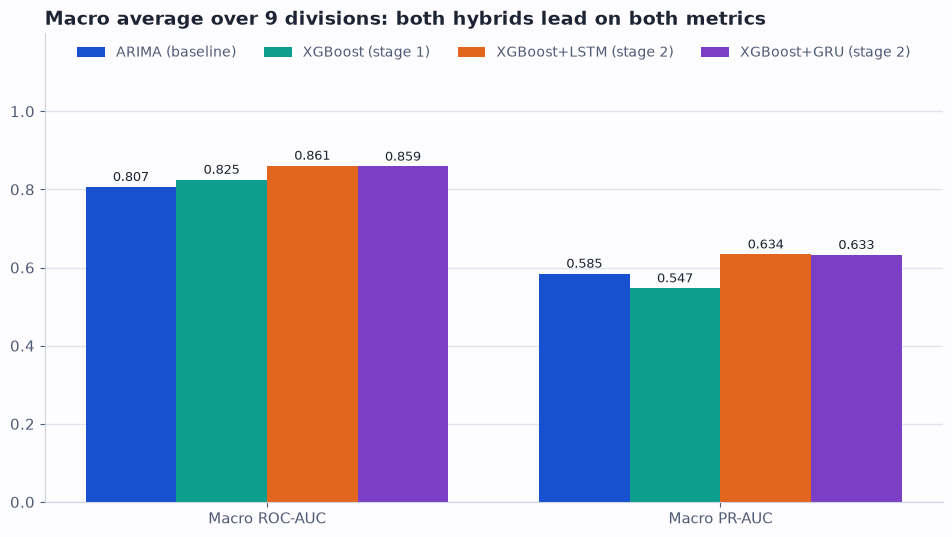

saved fig8_phase4_macro_summary.png


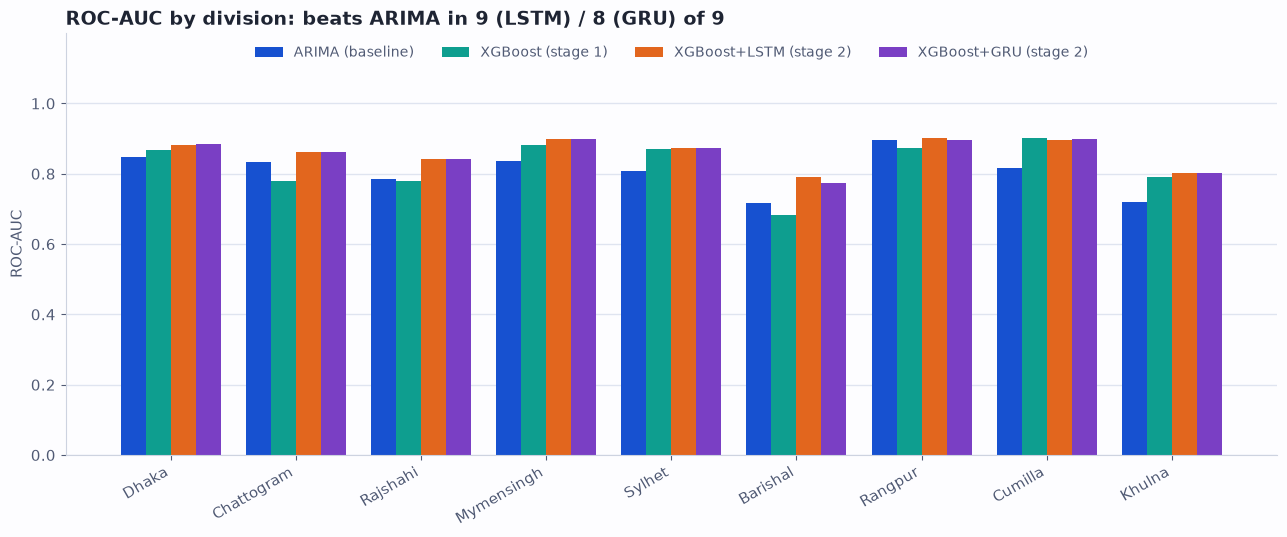

saved fig9_phase4_roc_auc.png


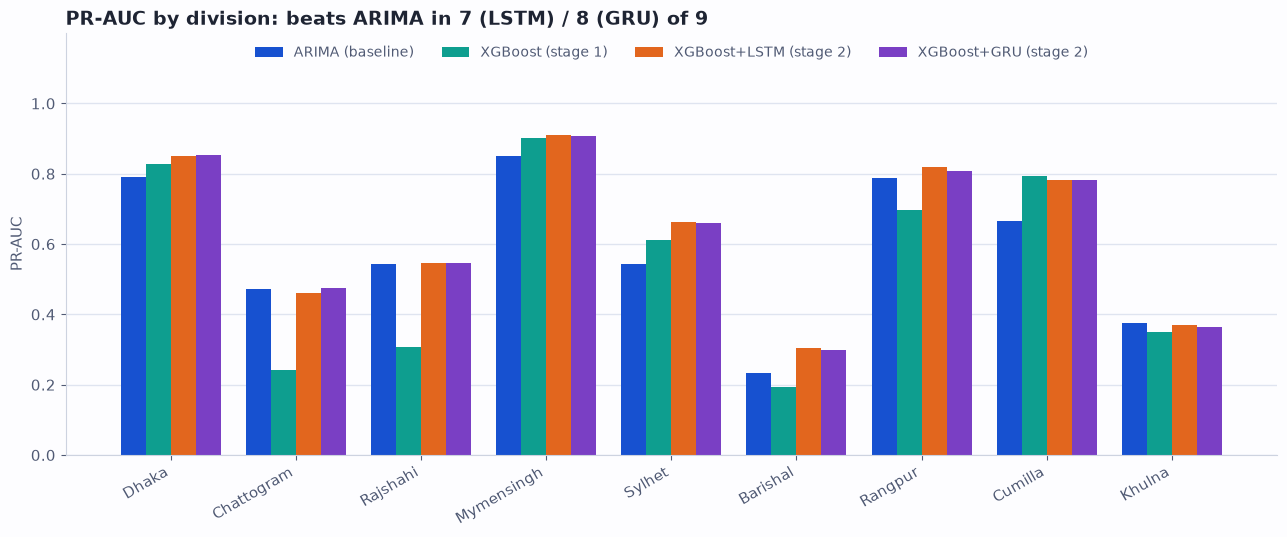

saved fig10_phase4_pr_auc.png


In [16]:
# ==============================================================================
# PROJECT: Predicting Load-Shedding Events in Bangladesh's Power Grid
# AUTHOR: Zahidul Alam (Jeonbuk National University)
# YEAR: 2026
#
# LICENSE: All Rights Reserved.
# This code is proprietary. It may not be copied, distributed, published, or
# used to train machine learning models or generative AI systems without explicit
# written permission from the author.
# ==============================================================================

# four-model figures (ARIMA, XGBoost, XGBoost+LSTM, XGBoost+GRU)
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

TABLES, FIGURES = "../outputs/tables", "../outputs/figures"
os.makedirs(FIGURES, exist_ok=True)

# Palette
BLUE, ORANGE, AQUA, PURPLE = "#1751D0", "#E2661E", "#0E9E8F", "#7A3FC4"
INK, INK2, GRID, SURF = "#1E2433", "#505A74", "#DFE4F0", "#FDFDFF"
plt.rcParams.update({"font.size": 11, "axes.edgecolor": "#CDD3E0", "axes.labelcolor": INK2,
                     "xtick.color": INK2, "ytick.color": INK2, "figure.facecolor": SURF,
                     "axes.facecolor": SURF, "axes.spines.top": False, "axes.spines.right": False})

MODELS = [("arima", "ARIMA (baseline)",       BLUE),
          ("xgb",   "XGBoost (stage 1)",      AQUA),
          ("lstm",  "XGBoost+LSTM (stage 2)", ORANGE),
          ("gru",   "XGBoost+GRU (stage 2)",  PURPLE)]

# Division rows only; macro recomputed from them
df = pd.read_csv(f"{TABLES}/phase4_xgb_gru.csv")
df = df[df["division"] != "Macro avg"].reset_index(drop=True)
macro = df.drop(columns="division").mean()
nd = len(df)

def wins(model, metric):
    """Divisions where `model` beats ARIMA on `metric`."""
    return int((df[f"{model}_{metric}"] > df[f"arima_{metric}"]).sum())

def grouped_bars(ax, labels, series, title, ylabel=None, rotate=0, annotate=False):
    n, x = len(series), np.arange(len(labels))
    w = 0.8 / n
    for j, (name, color, vals) in enumerate(series):
        bars = ax.bar(x + (j - (n - 1) / 2) * w, vals, w, color=color, label=name)
        if annotate:
            ax.bar_label(bars, fmt="%.3f", padding=2, fontsize=9, color=INK)
    ax.set_title(title, loc="left", color=INK, fontsize=14, fontweight="bold")
    if ylabel:
        ax.set_ylabel(ylabel)
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=rotate, ha="right" if rotate else "center")
    ax.set_ylim(0, 1.2)
    ax.set_yticks(np.arange(0, 1.01, 0.2))
    ax.grid(axis="y", color=GRID, linewidth=1)
    ax.set_axisbelow(True)
    ax.legend(frameon=False, labelcolor=INK2, ncol=4, loc="upper center", fontsize=10)

def save(fig, name):
    fig.tight_layout()
    fig.savefig(f"{FIGURES}/{name}", dpi=300, facecolor=SURF)
    plt.show()
    plt.close(fig)
    print("saved", name)

def division_series(metric):
    return [(label, color, df[f"{key}_{metric}"]) for key, label, color in MODELS]

# Fig 8: macro-average scoreboard
hyb_min = {m: min(macro[f"lstm_{m}"], macro[f"gru_{m}"]) for m in ("roc", "pr")}
others_max = {m: max(macro[f"arima_{m}"], macro[f"xgb_{m}"]) for m in ("roc", "pr")}
if all(hyb_min[m] > others_max[m] for m in ("roc", "pr")):
    t8 = f"Macro average over {nd} divisions: both hybrids lead on both metrics"
else:
    t8 = f"Macro average over {nd} divisions"
fig, ax = plt.subplots(figsize=(10, 5.5))
macro_series = [(label, color, [macro[f"{key}_roc"], macro[f"{key}_pr"]]) for key, label, color in MODELS]
grouped_bars(ax, ["Macro ROC-AUC", "Macro PR-AUC"], macro_series, t8, annotate=True)
save(fig, "fig8_phase4_macro_summary.png")

# Fig 9: ROC-AUC by division
fig, ax = plt.subplots(figsize=(13, 5.5))
grouped_bars(ax, df["division"], division_series("roc"),
             f"ROC-AUC by division: beats ARIMA in {wins('lstm','roc')} (LSTM) / {wins('gru','roc')} (GRU) of {nd}",
             ylabel="ROC-AUC", rotate=30)
save(fig, "fig9_phase4_roc_auc.png")

# Fig 10: PR-AUC by division
fig, ax = plt.subplots(figsize=(13, 5.5))
grouped_bars(ax, df["division"], division_series("pr"),
             f"PR-AUC by division: beats ARIMA in {wins('lstm','pr')} (LSTM) / {wins('gru','pr')} (GRU) of {nd}",
             ylabel="PR-AUC", rotate=30)
save(fig, "fig10_phase4_pr_auc.png")

In [17]:
# ==============================================================================
# PROJECT: Predicting Load-Shedding Events in Bangladesh's Power Grid
# AUTHOR: Zahidul Alam (Jeonbuk National University)
# YEAR: 2026
#
# LICENSE: All Rights Reserved.
# This code is proprietary. It may not be copied, distributed, published, or
# used to train machine learning models or generative AI systems without explicit
# written permission from the author.
# ==============================================================================

# save trained LSTM/GRU models + the arrays needed to reuse them (SHAP, ablation)
import os, json, torch

os.makedirs("../models", exist_ok=True)

for s, m in enumerate(models):          # LSTM seeds 0,1,2
    torch.save(m.state_dict(), f"../models/reslstm_seed{s}.pt")
for s, m in enumerate(gru_models):      # GRU seeds 0,1,2
    torch.save(m.state_dict(), f"../models/resgru_seed{s}.pt")

np.savez_compressed("../data/processed/seq_arrays.npz",
                    Xseq=Xseq, Xstat=Xstat, y_res=y_res, y_true=y_true, p_t=p_t,
                    div_id=div_id, is_test=is_test, date_t=date_t.astype(str).values,
                    tr_mask=tr_mask, val_mask=val_mask)

cfg = dict(window=W, divisions=divisions, n_seq=3, n_stat=10, hidden=32,
           seq_features=["residual", "xgb_prob", "actual_shed"],
           static_features=["xgb_prob_today"] + [f"onehot_{d}" for d in divisions],
           val_start="2023-07-04", seeds=[0, 1, 2],
           note="Final prob = clip(xgb_prob + mean over seeds of model output, 0, 1)")
json.dump(cfg, open("../models/seq_config.json", "w"), indent=2)

print(sorted(os.listdir("../models")))

['resgru_seed0.pt', 'resgru_seed1.pt', 'resgru_seed2.pt', 'reslstm_seed0.pt', 'reslstm_seed1.pt', 'reslstm_seed2.pt', 'seq_config.json']


In [18]:
# ==============================================================================
# PROJECT: Predicting Load-Shedding Events in Bangladesh's Power Grid
# AUTHOR: Zahidul Alam (Jeonbuk National University)
# YEAR: 2026
#
# LICENSE: All Rights Reserved.
# This code is proprietary. It may not be copied, distributed, published, or
# used to train machine learning models or generative AI systems without explicit
# written permission from the author.
# ==============================================================================

# reload from disk and confirm identical predictions
def load_preds(cls, prefix):
    outs = []
    for s in range(3):
        m = cls()
        m.load_state_dict(torch.load(f"../models/{prefix}_seed{s}.pt"))
        m.eval()
        with torch.no_grad():
            outs.append(m(T(Xseq), T(Xstat)).numpy())
    return np.clip(p_t + np.mean(outs, axis=0), 0, 1)

p_lstm_re = load_preds(ResLSTM, "reslstm")
p_gru_re  = load_preds(ResGRU,  "resgru")

print("LSTM max abs diff:", float(np.abs(p_lstm_re - p_lstm).max()))
print("GRU  max abs diff:", float(np.abs(p_gru_re  - p_gru ).max()))

LSTM max abs diff: 0.0
GRU  max abs diff: 0.0


In [19]:
# ==============================================================================
# PROJECT: Predicting Load-Shedding Events in Bangladesh's Power Grid
# AUTHOR: Zahidul Alam (Jeonbuk National University)
# YEAR: 2026
#
# LICENSE: All Rights Reserved.
# This code is proprietary. It may not be copied, distributed, published, or
# used to train machine learning models or generative AI systems without explicit
# written permission from the author.
# ==============================================================================

# same-threshold F1/recall/precision comparison
from sklearn.metrics import precision_recall_curve, precision_score, recall_score, f1_score
from statsmodels.tsa.arima.model import ARIMA
import warnings

MIN_VAL_POS = 5
def best_threshold(y_val, s_val):
    if y_val.sum() < MIN_VAL_POS:
        return 0.5, False
    prec, rec, thr = precision_recall_curve(y_val, s_val)
    f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-9, None)
    return float(thr[np.argmax(f1)]), True

date_to_row = {d: r for r, d in enumerate(pd.to_datetime(train["Date"]))}
rows = []

for i, d in enumerate(divisions):
    k_val = (div_id == i) & val_mask
    k_te  = (div_id == i) & is_test
    y_val, y_te = y_true[k_val], y_true[k_te]
    val_rows = [date_to_row[x] for x in date_t[k_val]]

    # ARIMA validation scores = in-sample fitted values on the same validation dates
    y_tr_l = train[f"{d}_load"].astype(float).values
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        arima_fit = ARIMA(y_tr_l, order=(1, 0, 1)).fit()
    arima_val = arima_fit.fittedvalues[val_rows]

    scores = {
        "ARIMA":   (arima_val,        p_arima[i]),
        "XGBoost": (p_t[k_val],       p_t[k_te]),
        "LSTM":    (p_lstm[k_val],    p_lstm[k_te]),
        "GRU":     (p_gru[k_val],     p_gru[k_te]),
    }
    for model, (s_val, s_te) in scores.items():
        thr, tuned = best_threshold(y_val, s_val)
        yhat = (s_te >= thr).astype(int)
        rows.append(dict(division=d, model=model, val_pos=int(y_val.sum()), thr=round(thr, 3), tuned=tuned,
                         recall=recall_score(y_te, yhat, zero_division=0),
                         precision=precision_score(y_te, yhat, zero_division=0),
                         f1=f1_score(y_te, yhat, zero_division=0)))

res_thr = pd.DataFrame(rows)
res_thr.to_csv("../outputs/tables/phase4_same_threshold.csv", index=False)

order = ["ARIMA", "XGBoost", "LSTM", "GRU"]
f1_tab = res_thr.pivot(index="division", columns="model", values="f1").loc[divisions, order].round(3)
f1_tab.loc["Macro F1"] = f1_tab.mean().round(3)
print(f1_tab.to_string())
print()
macro = res_thr.groupby("model")[["recall", "precision", "f1"]].mean().loc[order].round(3)
print(macro.to_string())
print()
print("divisions using fallback 0.5:", res_thr[(res_thr.model == "LSTM") & (~res_thr.tuned)].division.tolist())

model       ARIMA  XGBoost   LSTM    GRU
division                                
Dhaka       0.751    0.664  0.784  0.784
Chattogram  0.467    0.217  0.444  0.452
Rajshahi    0.523    0.344  0.536  0.536
Mymensingh  0.824    0.819  0.841  0.847
Sylhet      0.509    0.384  0.593  0.581
Barishal    0.233    0.133  0.421  0.421
Rangpur     0.716    0.710  0.720  0.733
Cumilla     0.617    0.701  0.740  0.699
Khulna      0.348    0.140  0.437  0.457
Macro F1    0.554    0.457  0.613  0.612

         recall  precision     f1
model                            
ARIMA     0.668      0.505  0.554
XGBoost   0.596      0.551  0.457
LSTM      0.681      0.596  0.613
GRU       0.670      0.601  0.612

divisions using fallback 0.5: ['Barishal']


In [21]:
# ==============================================================================
# PROJECT: Predicting Load-Shedding Events in Bangladesh's Power Grid
# AUTHOR: Zahidul Alam (Jeonbuk National University)
# YEAR: 2026
#
# LICENSE: All Rights Reserved.
# This code is proprietary. It may not be copied, distributed, published, or
# used to train machine learning models or generative AI systems without explicit
# written permission from the author.
# ==============================================================================

# Cell 4k-1: window-length ablation
import time

def build_seq(W):
    Xs, Xt, yr, yt, pt, dv, it, dt = [], [], [], [], [], [], [], []
    for i, d in enumerate(divisions):
        y_all = np.concatenate([train[f"{d}_shed"].values, test[f"{d}_shed"].values]).astype(float)
        p_all = np.concatenate([oof[d], xgb_test_prob[d]])
        r_all = y_all - p_all
        first = int(np.argmax(~np.isnan(p_all)))
        feats = np.stack([r_all, p_all, y_all], axis=1)
        onehot = np.eye(D)[i]
        for t in range(first + W, n_tr + n_te):
            Xs.append(feats[t-W:t]); Xt.append(np.concatenate([[p_all[t]], onehot]))
            yr.append(r_all[t]); yt.append(y_all[t]); pt.append(p_all[t])
            dv.append(i); it.append(t >= n_tr); dt.append(dates_all[t])
    d_ = dict(Xseq=np.array(Xs, dtype=np.float32), Xstat=np.array(Xt, dtype=np.float32),
              y_res=np.array(yr, dtype=np.float32), y_true=np.array(yt, dtype=np.float32),
              p_t=np.array(pt, dtype=np.float32), div_id=np.array(dv), is_test=np.array(it),
              date_t=pd.to_datetime(dt))
    d_["val_mask"] = (~d_["is_test"]) & (d_["date_t"] >= pd.Timestamp("2023-07-04"))
    d_["tr_mask"]  = (~d_["is_test"]) & ~d_["val_mask"]
    return d_

def fit_seq(cls, seed, d_, max_epochs=60, patience=10):
    torch.manual_seed(seed); np.random.seed(seed)
    xs_a, xt_a, y_a = T(d_["Xseq"][d_["tr_mask"]]), T(d_["Xstat"][d_["tr_mask"]]), T(d_["y_res"][d_["tr_mask"]])
    xs_v, xt_v, y_v = T(d_["Xseq"][d_["val_mask"]]), T(d_["Xstat"][d_["val_mask"]]), T(d_["y_res"][d_["val_mask"]])
    model = cls()
    opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
    loader = DataLoader(TensorDataset(xs_a, xt_a, y_a), batch_size=128, shuffle=True)
    best, best_state, bad = 1e9, None, 0
    for ep in range(max_epochs):
        model.train()
        for xs, xt, y in loader:
            opt.zero_grad()
            loss = ((model(xs, xt) - y) ** 2).mean()
            loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            v = ((model(xs_v, xt_v) - y_v) ** 2).mean().item()
        if v < best - 1e-5:
            best, bad = v, 0
            best_state = {k: t.clone() for k, t in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience: break
    model.load_state_dict(best_state); model.eval()
    return model, best, (y_v ** 2).mean().item()

rows = []
for W_ in [7, 14, 21]:
    t0 = time.time()
    d_ = build_seq(W_)
    assert not np.isnan(d_["Xseq"]).any() and not np.isnan(d_["Xstat"]).any()
    for name, cls in [("LSTM", ResLSTM), ("GRU", ResGRU)]:
        preds, vals = [], []
        for s in [0, 1, 2]:
            m, v, zero_v = fit_seq(cls, s, d_)
            vals.append(v)
            with torch.no_grad():
                preds.append(m(T(d_["Xseq"]), T(d_["Xstat"])).numpy())
        p_h = np.clip(d_["p_t"] + np.mean(preds, axis=0), 0, 1)
        rocs, prs = [], []
        for i in range(len(divisions)):
            k = (d_["div_id"] == i) & d_["is_test"]
            rocs.append(roc_auc_score(d_["y_true"][k], p_h[k]))
            prs.append(average_precision_score(d_["y_true"][k], p_h[k]))
        rows.append(dict(window=W_, model=name, n_train=int(d_["tr_mask"].sum()),
                         val_mse=round(float(np.mean(vals)), 4), val_mse_xgb=round(zero_v, 4),
                         macro_roc=round(float(np.mean(rocs)), 3), macro_pr=round(float(np.mean(prs)), 3)))
        print(rows[-1])
    print(f"window {W_} done in {time.time() - t0:.0f}s\n")

res_win = pd.DataFrame(rows)
res_win.to_csv("../outputs/tables/phase4_window_ablation.csv", index=False)
print(res_win.to_string(index=False))

{'window': 7, 'model': 'LSTM', 'n_train': 9432, 'val_mse': 0.0928, 'val_mse_xgb': 0.1052, 'macro_roc': 0.859, 'macro_pr': 0.634}
{'window': 7, 'model': 'GRU', 'n_train': 9432, 'val_mse': 0.0927, 'val_mse_xgb': 0.1052, 'macro_roc': 0.858, 'macro_pr': 0.638}
window 7 done in 129s

{'window': 14, 'model': 'LSTM', 'n_train': 9369, 'val_mse': 0.0925, 'val_mse_xgb': 0.1052, 'macro_roc': 0.861, 'macro_pr': 0.634}
{'window': 14, 'model': 'GRU', 'n_train': 9369, 'val_mse': 0.0925, 'val_mse_xgb': 0.1052, 'macro_roc': 0.859, 'macro_pr': 0.633}
window 14 done in 130s

{'window': 21, 'model': 'LSTM', 'n_train': 9306, 'val_mse': 0.0926, 'val_mse_xgb': 0.1052, 'macro_roc': 0.861, 'macro_pr': 0.631}
{'window': 21, 'model': 'GRU', 'n_train': 9306, 'val_mse': 0.0925, 'val_mse_xgb': 0.1052, 'macro_roc': 0.861, 'macro_pr': 0.632}
window 21 done in 393s

 window model  n_train  val_mse  val_mse_xgb  macro_roc  macro_pr
      7  LSTM     9432   0.0928       0.1052      0.859     0.634
      7   GRU     9432